<a href="https://colab.research.google.com/github/kavisaranithangavel-dev/Creation-of-Security-Operations-Dashboard-for-Threat-Detection-with-Risk-Mitigation-Analytics/blob/main/SOC_Python_Practice.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Python Practice — Security Operations
Python basics for SOC analysts, then log analysis and detection rules with Pandas.


# PART 1 — Python Basics for SOC Analysts

Variables, data types and printing a simple alert summary

In [ ]:
alert_id = 4521
hostname = "web-prod-01"
severity_score = 87.5
is_confirmed = True

print("Alert ID:", alert_id)
print("Host:", hostname)
print("Severity Score:", severity_score)
print("Confirmed:", is_confirmed)
print(type(alert_id), type(hostname), type(severity_score), type(is_confirmed))

Alert ID: 4521
Host: web-prod-01
Severity Score: 87.5
Confirmed: True
<class 'int'> <class 'str'> <class 'float'> <class 'bool'>


Lists: store indicators of compromise (IOCs)

In [ ]:
malicious_ips = ["198.51.100.7", "198.51.100.99", "203.0.113.50"]

print(malicious_ips)
print("First:", malicious_ips[0])
print("Count:", len(malicious_ips))

malicious_ips.append("192.0.2.200")
print("After adding:", malicious_ips)

['198.51.100.7', '198.51.100.99', '203.0.113.50']
First: 198.51.100.7
Count: 3
After adding: ['198.51.100.7', '198.51.100.99', '203.0.113.50', '192.0.2.200']


Dictionary: represent one security alert

In [ ]:
alert = {
    "id": 101,
    "type": "Brute Force",
    "source_ip": "198.51.100.7",
    "severity": "High",
    "status": "Open"
}

print(alert["type"])
alert["status"] = "Investigating"
print(alert)

Brute Force
{'id': 101, 'type': 'Brute Force', 'source_ip': '198.51.100.7', 'severity': 'High', 'status': 'Investigating'}


List of dictionaries: a small alert queue

In [ ]:
alert_queue = [
    {"id": 1, "type": "Phishing",         "risk": 82},
    {"id": 2, "type": "Port Scan",        "risk": 25},
    {"id": 3, "type": "Ransomware",       "risk": 98},
    {"id": 4, "type": "Impossible Travel","risk": 64},
]

for a in alert_queue:
    print(a["id"], a["type"], a["risk"])

1 Phishing 82
2 Port Scan 25
3 Ransomware 98
4 Impossible Travel 64


Function: triage an alert based on risk score

In [ ]:
def triage(score):
    if score >= 90:
        return "P1 - Escalate immediately"
    elif score >= 70:
        return "P2 - Investigate within 1 hour"
    elif score >= 40:
        return "P3 - Investigate today"
    else:
        return "P4 - Monitor"

for a in alert_queue:
    print(a["type"], "->", triage(a["risk"]))

Phishing -> P2 - Investigate within 1 hour
Port Scan -> P4 - Monitor
Ransomware -> P1 - Escalate immediately
Impossible Travel -> P3 - Investigate today


Sort the alert queue so the highest risk comes first

In [ ]:
sorted_queue = sorted(alert_queue, key=lambda a: a["risk"], reverse=True)

for a in sorted_queue:
    print(a["id"], a["type"], a["risk"])

3 Ransomware 98
1 Phishing 82
4 Impossible Travel 64
2 Port Scan 25


Sets: match observed IPs against a threat-intel blocklist

In [ ]:
blocklist = {"198.51.100.7", "198.51.100.99", "203.0.113.50"}
observed  = {"192.0.2.44", "198.51.100.7", "203.0.113.10", "203.0.113.50"}

print("Matches (IOC hits):", observed & blocklist)
print("Clean IPs:", observed - blocklist)
print("All unique IPs:", observed | blocklist)

Matches (IOC hits): {'203.0.113.50', '198.51.100.7'}
Clean IPs: {'192.0.2.44', '203.0.113.10'}
All unique IPs: {'192.0.2.44', '203.0.113.10', '203.0.113.50', '198.51.100.7', '198.51.100.99'}


Tuples: immutable (host, port) pairs, and a check for risky open ports

In [ ]:
open_ports = [("web-prod-01", 443), ("db-prod-01", 3306), ("dev-vm-03", 23), ("hr-laptop-07", 3389)]
risky_ports = {23: "Telnet", 3389: "RDP", 445: "SMB"}

for host, port in open_ports:
    if port in risky_ports:
        print(f"WARNING: {host} exposes {risky_ports[port]} (port {port})")

Loops: count failed logins in a list of events

In [ ]:
results = ["FAILED", "FAILED", "SUCCESS", "FAILED", "FAILED", "SUCCESS", "FAILED"]

failed = 0
for r in results:
    if r == "FAILED":
        failed += 1

print("Failed logins:", failed)
print("Failure rate:", round(failed / len(results) * 100, 1), "%")

Failed logins: 5
Failure rate: 71.4 %


While loop with break: lock an account after 3 failed attempts

In [ ]:
attempts = 0
max_attempts = 3
simulated_inputs = ["pass1", "pass2", "pass3", "pass4"]

while attempts < len(simulated_inputs):
    attempts += 1
    print(f"Attempt {attempts}: wrong password")
    if attempts == max_attempts:
        print("Account locked!")
        break

Attempt 1: wrong password
Attempt 2: wrong password
Attempt 3: wrong password
Account locked!


String handling: parse one log line

In [ ]:
log_line = "2026-11-05 22:01:20 FAILED LOGIN user=arun ip=203.0.113.10"

parts = log_line.split()
print(parts)

date, time, status = parts[0], parts[1], parts[2]
user = parts[4].split("=")[1]
ip   = parts[5].split("=")[1]
print(date, time, status, user, ip)

['2026-11-05', '22:01:20', 'FAILED', 'LOGIN', 'user=arun', 'ip=203.0.113.10']
2026-11-05 22:01:20 FAILED arun 203.0.113.10


Regular expressions: extract every IP address from raw log text

In [ ]:
import re

raw_logs = """
Nov 05 22:01:20 sshd[991]: Failed password for root from 198.51.100.7 port 51122 ssh2
Nov 05 22:01:25 sshd[991]: Failed password for admin from 198.51.100.7 port 51130 ssh2
Nov 05 22:03:10 sshd[994]: Accepted password for anu from 192.0.2.44 port 40012 ssh2
Nov 05 22:04:00 sshd[995]: Failed password for invalid user test from 203.0.113.10 port 22001 ssh2
"""

ip_pattern = r"\b(?:\d{1,3}\.){3}\d{1,3}\b"
ips = re.findall(ip_pattern, raw_logs)
print(ips)

['198.51.100.7', '198.51.100.7', '192.0.2.44', '203.0.113.10']


Count failed SSH attempts per IP using a dictionary

In [ ]:
from collections import Counter

failed_ips = []
for line in raw_logs.strip().splitlines():
    if "Failed password" in line:
        failed_ips.append(re.search(ip_pattern, line).group())

counts = Counter(failed_ips)
print(counts)
print("Top offender:", counts.most_common(1))

Counter({'198.51.100.7': 2, '203.0.113.10': 1})
Top offender: [('198.51.100.7', 2)]


Hash a file's contents (SHA-256), the same idea used to compare file hashes against malware databases

In [ ]:
import hashlib

sample = b"This is a sample file body"
print("SHA-256:", hashlib.sha256(sample).hexdigest())
print("MD5    :", hashlib.md5(sample).hexdigest())

SHA-256: 9666ffcc5041350b75d8cda015a43f0a78493b0e923d492016bd22ae684d52a2
MD5    : 819dfbdc5fdf2853f91faf36ee5cdede


Password strength checker function

In [ ]:
def check_password(pw):
    issues = []
    if len(pw) < 12:
        issues.append("shorter than 12 characters")
    if not any(c.isupper() for c in pw):
        issues.append("no uppercase letter")
    if not any(c.isdigit() for c in pw):
        issues.append("no digit")
    if not any(not c.isalnum() for c in pw):
        issues.append("no special character")
    return "Strong" if not issues else "Weak: " + ", ".join(issues)

for p in ["password", "Summer2026", "T!ger_Moon_88x"]:
    print(p, "->", check_password(p))

password -> Weak: shorter than 12 characters, no uppercase letter, no digit, no special character
Summer2026 -> Weak: shorter than 12 characters, no special character
T!ger_Moon_88x -> Strong


Exception handling: safely read a log file that may not exist

In [ ]:
try:
    with open("missing_auth.log") as f:
        data = f.read()
except FileNotFoundError:
    print("Log file not found - check the path or log collector status.")

Log file not found - check the path or log collector status.


File handling: write alerts to a file, then read them back

In [ ]:
with open("alerts_report.txt", "w") as f:
    for a in alert_queue:
        f.write(f"{a['id']},{a['type']},{a['risk']}\n")

with open("alerts_report.txt") as f:
    print(f.read())

1,Phishing,82
2,Port Scan,25
3,Ransomware,98
4,Impossible Travel,64



# PART 2 — Log Analysis and Detection with Pandas

Create the sample alert, login and blocklist data as DataFrames

In [ ]:
import pandas as pd

alerts_df = pd.DataFrame({
    "alert_id":    [1, 2, 3, 4, 5, 6, 7, 8, 9],
    "asset":       ["web-prod-01", "db-prod-01", "hr-laptop-07", "dev-vm-03", "web-prod-01",
                    "vpn-gw-01", "hr-laptop-07", "db-prod-01", "web-prod-01"],
    "analyst":     ["Meera", "Divya", "Meera", "Suresh", "Karthik", "Karthik", "Meera", "Divya", "Suresh"],
    "alert_type":  ["Brute Force", "SQL Injection", "Phishing Email", "Port Scan", "Malware Detected",
                    "Impossible Travel", "Phishing Email", "Data Exfiltration", "Brute Force"],
    "mitre_tactic":["Credential Access", "Initial Access", "Initial Access", "Discovery", "Execution",
                    "Initial Access", "Initial Access", "Exfiltration", "Credential Access"],
    "severity":    ["High", "Critical", "Medium", "Low", "Critical", "High", "High", "Critical", "Medium"],
    "status":      ["Closed", "Investigating", "Closed", "Closed", "Open", "Open", "Closed", "Investigating", "Closed"],
    "created_at":  ["2026-11-01 02:10:00", "2026-11-01 09:30:00", "2026-11-02 10:00:00", "2026-11-02 23:15:00",
                    "2026-11-03 01:45:00", "2026-11-03 04:20:00", "2026-11-04 08:50:00", "2026-11-05 14:05:00",
                    "2026-11-05 22:40:00"],
    "resolved_at": ["2026-11-01 03:00:00", None, "2026-11-02 11:30:00", "2026-11-03 00:05:00",
                    None, None, "2026-11-04 10:10:00", None, "2026-11-06 00:10:00"],
})

logins_df = pd.DataFrame({
    "username":   ["arun"]*4 + ["rahul"]*2 + ["anu"]*2 + ["admin"]*4,
    "source_ip":  ["203.0.113.10"]*4 + ["198.51.100.7"]*2 + ["192.0.2.44", "198.51.100.99"] + ["198.51.100.7"]*4,
    "country":    ["IN"]*4 + ["RU"]*2 + ["IN", "CN"] + ["RU"]*4,
    "result":     ["FAILED", "FAILED", "FAILED", "SUCCESS", "FAILED", "FAILED", "SUCCESS", "SUCCESS",
                   "FAILED", "FAILED", "FAILED", "FAILED"],
    "event_time": ["2026-11-05 22:01:00", "2026-11-05 22:01:20", "2026-11-05 22:01:45", "2026-11-05 22:02:10",
                   "2026-11-05 23:15:00", "2026-11-05 23:15:10", "2026-11-06 09:00:00", "2026-11-06 09:20:00",
                   "2026-11-06 01:00:00", "2026-11-06 01:00:05", "2026-11-06 01:00:09", "2026-11-06 01:00:14"],
})

blocklist_df = pd.DataFrame({
    "ip":         ["198.51.100.7", "198.51.100.99"],
    "reason":     ["Repeated brute force", "Known malicious ASN"],
    "confidence": [95, 70],
})

print(alerts_df.head())
print(logins_df.head())
print(blocklist_df)

   alert_id         asset  analyst        alert_type       mitre_tactic  \
0         1   web-prod-01    Meera       Brute Force  Credential Access   
1         2    db-prod-01    Divya     SQL Injection     Initial Access   
2         3  hr-laptop-07    Meera    Phishing Email     Initial Access   
3         4     dev-vm-03   Suresh         Port Scan          Discovery   
4         5   web-prod-01  Karthik  Malware Detected          Execution   

   severity         status           created_at          resolved_at  
0      High         Closed  2026-11-01 02:10:00  2026-11-01 03:00:00  
1  Critical  Investigating  2026-11-01 09:30:00                 None  
2    Medium         Closed  2026-11-02 10:00:00  2026-11-02 11:30:00  
3       Low         Closed  2026-11-02 23:15:00  2026-11-03 00:05:00  
4  Critical           Open  2026-11-03 01:45:00                 None  
  username     source_ip country   result           event_time
0     arun  203.0.113.10      IN   FAILED  2026-11-05 22:01:

Explore the data

In [ ]:
print(alerts_df.shape)
print(alerts_df.dtypes)
print(alerts_df.isnull().sum())

(9, 9)
alert_id         int64
asset           object
analyst         object
alert_type      object
mitre_tactic    object
severity        object
status          object
created_at      object
resolved_at     object
dtype: object
alert_id        0
asset           0
analyst         0
alert_type      0
mitre_tactic    0
severity        0
status          0
created_at      0
resolved_at     4
dtype: int64


Convert the timestamp columns to real datetimes

In [ ]:
alerts_df["created_at"]  = pd.to_datetime(alerts_df["created_at"])
alerts_df["resolved_at"] = pd.to_datetime(alerts_df["resolved_at"])
logins_df["event_time"]  = pd.to_datetime(logins_df["event_time"])

print(alerts_df.dtypes)

alert_id                 int64
asset                   object
analyst                 object
alert_type              object
mitre_tactic            object
severity                object
status                  object
created_at      datetime64[ns]
resolved_at     datetime64[ns]
dtype: object


Calculate time-to-resolve in minutes and the overall MTTR

In [ ]:
alerts_df["resolve_minutes"] = (alerts_df["resolved_at"] - alerts_df["created_at"]).dt.total_seconds() / 60

print(alerts_df[["alert_id", "alert_type", "resolve_minutes"]])
print("MTTR (minutes):", round(alerts_df["resolve_minutes"].mean(), 1))

   alert_id         alert_type  resolve_minutes
0         1        Brute Force             50.0
1         2      SQL Injection              NaN
2         3     Phishing Email             90.0
3         4          Port Scan             50.0
4         5   Malware Detected              NaN
5         6  Impossible Travel              NaN
6         7     Phishing Email             80.0
7         8  Data Exfiltration              NaN
8         9        Brute Force             90.0
MTTR (minutes): 72.0


MTTR by severity

In [ ]:
print(alerts_df.groupby("severity")["resolve_minutes"].mean().round(1))

severity
Critical     NaN
High        65.0
Low         50.0
Medium      90.0
Name: resolve_minutes, dtype: float64


Alerts by type and by severity

In [ ]:
print(alerts_df["alert_type"].value_counts())
print()
print(alerts_df["severity"].value_counts())

alert_type
Brute Force          2
Phishing Email       2
SQL Injection        1
Port Scan            1
Malware Detected     1
Impossible Travel    1
Data Exfiltration    1
Name: count, dtype: int64

severity
High        3
Critical    3
Medium      2
Low         1
Name: count, dtype: int64


Pivot table: alert type vs. severity

In [ ]:
pivot = pd.pivot_table(alerts_df, index="alert_type", columns="severity",
                       values="alert_id", aggfunc="count", fill_value=0)
print(pivot)

severity           Critical  High  Low  Medium
alert_type                                    
Brute Force               0     1    0       1
Data Exfiltration         1     0    0       0
Impossible Travel         0     1    0       0
Malware Detected          1     0    0       0
Phishing Email            0     1    0       1
Port Scan                 0     0    1       0
SQL Injection             1     0    0       0


Alerts by hour of day (find your busiest hours)

In [ ]:
alerts_df["hour"] = alerts_df["created_at"].dt.hour
print(alerts_df.groupby("hour").size())

hour
1     1
2     1
4     1
8     1
9     1
10    1
14    1
22    1
23    1
dtype: int64


Filter: unresolved Critical or High alerts (your active incident list)

In [ ]:
active = alerts_df[
    (alerts_df["severity"].isin(["Critical", "High"])) &
    (alerts_df["resolved_at"].isnull())
]
print(active[["alert_id", "alert_type", "severity", "status"]])

   alert_id         alert_type  severity         status
1         2      SQL Injection  Critical  Investigating
4         5   Malware Detected  Critical           Open
5         6  Impossible Travel      High           Open
7         8  Data Exfiltration  Critical  Investigating


Add an SLA column. SLA targets: Critical = 30 min, High = 60 min, Medium = 240 min, Low = 480 min. Flag closed alerts that breached SLA.

In [ ]:
sla_minutes = {"Critical": 30, "High": 60, "Medium": 240, "Low": 480}

alerts_df["sla_target"] = alerts_df["severity"].map(sla_minutes)
alerts_df["sla_breached"] = alerts_df["resolve_minutes"] > alerts_df["sla_target"]

print(alerts_df[["alert_id", "severity", "resolve_minutes", "sla_target", "sla_breached"]])

   alert_id  severity  resolve_minutes  sla_target  sla_breached
0         1      High             50.0          60         False
1         2  Critical              NaN          30         False
2         3    Medium             90.0         240         False
3         4       Low             50.0         480         False
4         5  Critical              NaN          30         False
5         6      High              NaN          60         False
6         7      High             80.0          60          True
7         8  Critical              NaN          30         False
8         9    Medium             90.0         240         False


MITRE ATT&CK tactic frequency

In [ ]:
print(alerts_df["mitre_tactic"].value_counts())

mitre_tactic
Initial Access       4
Credential Access    2
Discovery            1
Execution            1
Exfiltration         1
Name: count, dtype: int64


### Detection rules on login data

Rule 1 — Brute force: 3+ failed logins from the same IP

In [ ]:
failed = logins_df[logins_df["result"] == "FAILED"]
by_ip = failed.groupby("source_ip").size().reset_index(name="failures")
brute_force = by_ip[by_ip["failures"] >= 3]
print(brute_force)

      source_ip  failures
0  198.51.100.7         6
1  203.0.113.10         3


Rule 2 — Failed logins inside a time window: 3+ failures from one IP within 60 seconds

In [ ]:
suspects = []
for ip, g in failed.sort_values("event_time").groupby("source_ip"):
    times = g["event_time"].tolist()
    for i in range(len(times) - 2):
        if (times[i + 2] - times[i]).total_seconds() <= 60:
            suspects.append(ip)
            break

print("IPs with burst failures:", suspects)

IPs with burst failures: ['198.51.100.7', '203.0.113.10']


Rule 3 — Success after failures (possible account takeover)

In [ ]:
takeover = []
for (user, ip), g in logins_df.sort_values("event_time").groupby(["username", "source_ip"]):
    results = g["result"].tolist()
    if "SUCCESS" in results and "FAILED" in results[:results.index("SUCCESS")]:
        takeover.append((user, ip))

print("Possible account takeover:", takeover)

Possible account takeover: [('arun', '203.0.113.10')]


Rule 4 — Users logging in from more than one country

In [ ]:
ok = logins_df[logins_df["result"] == "SUCCESS"]
countries = ok.groupby("username")["country"].nunique()
print(countries[countries > 1])

username
anu    2
Name: country, dtype: int64


Rule 5 — Match logins against the IOC blocklist

In [ ]:
hits = logins_df.merge(blocklist_df, left_on="source_ip", right_on="ip", how="inner")
print(hits[["username", "source_ip", "result", "reason", "confidence"]])

  username      source_ip   result                reason  confidence
0    rahul   198.51.100.7   FAILED  Repeated brute force          95
1    rahul   198.51.100.7   FAILED  Repeated brute force          95
2      anu  198.51.100.99  SUCCESS   Known malicious ASN          70
3    admin   198.51.100.7   FAILED  Repeated brute force          95
4    admin   198.51.100.7   FAILED  Repeated brute force          95
5    admin   198.51.100.7   FAILED  Repeated brute force          95
6    admin   198.51.100.7   FAILED  Repeated brute force          95


Build a simple risk score per IP: 10 points per failed login, plus the blocklist confidence if the IP is on the list

In [ ]:
score = failed.groupby("source_ip").size().mul(10).rename("fail_points").to_frame()
score = score.join(blocklist_df.set_index("ip")["confidence"].rename("ioc_points")).fillna(0)
score["risk_score"] = score["fail_points"] + score["ioc_points"]
score["action"] = score["risk_score"].apply(
    lambda s: "Block now" if s >= 80 else "Investigate" if s >= 30 else "Monitor"
)
print(score.sort_values("risk_score", ascending=False))

              fail_points  ioc_points  risk_score       action
source_ip                                                     
198.51.100.7           60        95.0       155.0    Block now
203.0.113.10           30         0.0        30.0  Investigate


Visualize alerts by severity

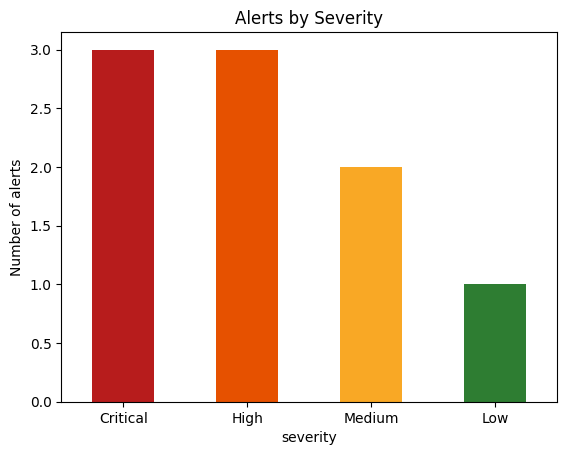

In [ ]:
import matplotlib.pyplot as plt

counts = alerts_df["severity"].value_counts().reindex(["Critical", "High", "Medium", "Low"]).fillna(0)
counts.plot(kind="bar", title="Alerts by Severity", color=["#b71c1c", "#e65100", "#f9a825", "#2e7d32"])
plt.ylabel("Number of alerts")
plt.xticks(rotation=0)
plt.show()

Export a daily SOC summary report to CSV

In [ ]:
summary = {
    "total_alerts": len(alerts_df),
    "open_or_investigating": int(alerts_df["status"].isin(["Open", "Investigating"]).sum()),
    "critical_alerts": int((alerts_df["severity"] == "Critical").sum()),
    "mttr_minutes": round(alerts_df["resolve_minutes"].mean(), 1),
    "sla_breaches": int(alerts_df["sla_breached"].sum()),
    "ips_flagged": len(brute_force),
}

report = pd.DataFrame([summary])
report.to_csv("soc_daily_summary.csv", index=False)
print(report.T)

                          0
total_alerts            9.0
open_or_investigating   4.0
critical_alerts         3.0
mttr_minutes           72.0
sla_breaches            1.0
ips_flagged             2.0
